# 01 · EDO de una celda: equilibrios, estabilidad y umbral de ignición

Modelo completo (ver `docs/modelo.md`):

$$\frac{\partial T}{\partial t} = \kappa \nabla^2 T - \mathbf{v}\cdot\nabla T + A\,\beta\, r(T) - C\,(T - T_\infty), \qquad \frac{\partial \beta}{\partial t} = -\varepsilon\, \beta\, r(T)$$

Para una sola celda aislada no hay difusión ni viento, y queda un sistema de dos EDO en $(T, \beta)$. Este notebook:

1. Justifica la forma de la tasa de reacción $r(T)$.
2. Adimensionaliza el sistema.
3. Analiza la EDO de $T$ con combustible congelado: equilibrios, tabla de signos, línea de fase y bifurcación.
4. Estudia el plano de fase completo $(T, \beta)$ y el umbral de ignición.
5. Fija los valores por defecto de los parámetros.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from scipy.integrate import solve_ivp

sys.path.insert(0, str(Path.cwd().parent))
from app.contracts import BURNING_T_U8, T_U8_MAX, T_U8_MIN
from app.solver.model import (
    PARAM_RANGES, PhysicalParams, cell_rhs_u, critical_fuel, frozen_fuel_df,
    frozen_fuel_equilibria, frozen_fuel_f, ignition_threshold, length_scale,
    reaction_rate_u, speed_scale, time_scale, to_dimensionless, u_to_T, T_to_u,
)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
p = PhysicalParams()
d = to_dimensionless(p)
T_BURNING = T_U8_MIN + BURNING_T_U8 / 255 * (T_U8_MAX - T_U8_MIN)  # "ardiendo" en pantalla
u_burn = float(T_to_u(T_BURNING, p))
print(p)
print(d)
print(f"Umbral visual de 'ardiendo': {T_BURNING:.0f} K  (u = {u_burn:.3f})")

PhysicalParams(kappa=0.5, A=1500.0, B=690.0, C=0.1, eps=0.8, T_inf=300.0)
Dimensionless(a=50.0, b=2.3, e=8.0)
Umbral visual de 'ardiendo': 771 K  (u = 1.569)


## 1. Forma de la tasa de reacción

El plan proponía $r(T) = e^{-B/T}$, pero esa forma tiene un problema: **nunca vale cero**. A temperatura ambiente el combustible se consume a ritmo $\varepsilon\, e^{-B/T_\infty}$, así que un bosque sin ignición se "quema" solo con el tiempo. Para que esa fuga sea despreciable hay que tomar $B \gtrsim 20\,T_\infty$, pero entonces la rama caliente estable queda a temperaturas absurdas.

Por eso usamos la ley de Arrhenius desplazada (Mandel et al., 2008; Asensio y Ferragut, 2002):

$$r(T) = \begin{cases} e^{-B/(T - T_\infty)} & T > T_\infty \\ 0 & T \le T_\infty \end{cases}$$

Es exactamente cero a temperatura ambiente, con todas sus derivadas, y conserva la forma de umbral. Abajo se comparan las dos con los valores por defecto.

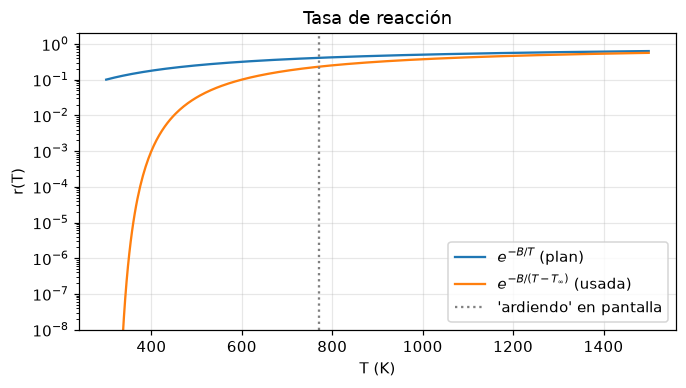

Con e^(-B/T) y B = 690 K, a T_inf el combustible decae con tiempo 1/(eps·r) = 12.5 s.
  b = B/T_inf = 10: tiempo de fuga = 2.75e+04 s
  b = B/T_inf = 20: tiempo de fuga = 6.06e+08 s
  b = B/T_inf = 30: tiempo de fuga = 1.34e+13 s


In [2]:
T = np.linspace(p.T_inf, 1500, 400)
r_plan = np.exp(-p.B / T)
r_used = reaction_rate_u(T_to_u(T, p), d.b)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(T, r_plan, label=r"$e^{-B/T}$ (plan)")
ax.semilogy(T[1:], r_used[1:], label=r"$e^{-B/(T-T_\infty)}$ (usada)")
ax.axvline(T_BURNING, color="gray", ls=":", label="'ardiendo' en pantalla")
ax.set(xlabel="T (K)", ylabel="r(T)", title="Tasa de reacción", ylim=(1e-8, 2))
ax.legend()
plt.show()

leak = p.eps * np.exp(-p.B / p.T_inf)
print(f"Con e^(-B/T) y B = {p.B:.0f} K, a T_inf el combustible decae con tiempo 1/(eps·r) = {1/leak:.1f} s.")
for b_big in (10, 20, 30):
    print(f"  b = B/T_inf = {b_big}: tiempo de fuga = {1/(p.eps*np.exp(-b_big)):.2e} s")

Con la forma del plan y nuestros valores, el bosque entero se consumiría en pocos segundos sin haber encendido nada. Para evitarlo con esa forma habría que usar $b \ge 20$, y en el análisis de la sección 3 se ve que entonces la rama caliente estable se va a miles de grados. La forma desplazada resuelve los dos problemas: **sin ignición no pasa nada**, que es justo la primera prueba que pide el plan para el solver.

## 2. Adimensionalización

Definimos

$$u = \frac{T - T_\infty}{T_\infty}, \qquad \tau = C\,t, \qquad \boldsymbol{\xi} = \frac{\mathbf{x}}{L},\quad L = \sqrt{\kappa / C}$$

y el sistema queda

$$u_\tau = \nabla_\xi^2 u - \mathbf{w}\cdot\nabla_\xi u + a\,\beta\, e^{-b/u} - u, \qquad \beta_\tau = -e\,\beta\, e^{-b/u}$$

con cuatro grupos adimensionales:

| Grupo | Definición | Significado |
|---|---|---|
| $a$ | $A / (C\,T_\infty)$ | calor liberado frente a pérdidas |
| $b$ | $B / T_\infty$ | energía de activación (qué tan "de umbral" es la reacción) |
| $e$ | $\varepsilon / C$ | rapidez con que se agota el combustible frente a las pérdidas |
| $\mathbf{w}$ | $\mathbf{v} / \sqrt{\kappa C}$ | viento (número de Péclet) |

In [3]:
rows = [
    ("a", d.a), ("b", d.b), ("e", d.e),
    ("L = √(κ/C)  [m]", length_scale(p)),
    ("1/C  [s]", time_scale(p)),
    ("√(κC)  [m/s]", speed_scale(p)),
]
display(Markdown("| Cantidad | Valor |\n|---|---|\n" + "\n".join(f"| {k} | {v:.4g} |" for k, v in rows)))

| Cantidad | Valor |
|---|---|
| a | 50 |
| b | 2.3 |
| e | 8 |
| L = √(κ/C)  [m] | 2.236 |
| 1/C  [s] | 10 |
| √(κC)  [m/s] | 0.2236 |

## 3. Combustible congelado: la EDO de $u$

La reacción consume combustible a ritmo $e\,\beta\, r$, pero mientras la celda no se enciende $r \approx 0$ y $\beta$ prácticamente no cambia. Por eso, para decidir **si** una celda se enciende, podemos tratar $\beta$ como constante y estudiar una sola EDO autónoma:

$$\frac{du}{d\tau} = f(u) = \underbrace{a\,\beta\, e^{-b/u}}_{\text{calor de la reacción}} - \underbrace{u}_{\text{pérdidas}}$$

Los equilibrios son los cortes de la curva de calor con la recta de pérdidas. Son estables si $f'(u^*) < 0$ e inestables si $f'(u^*) > 0$.

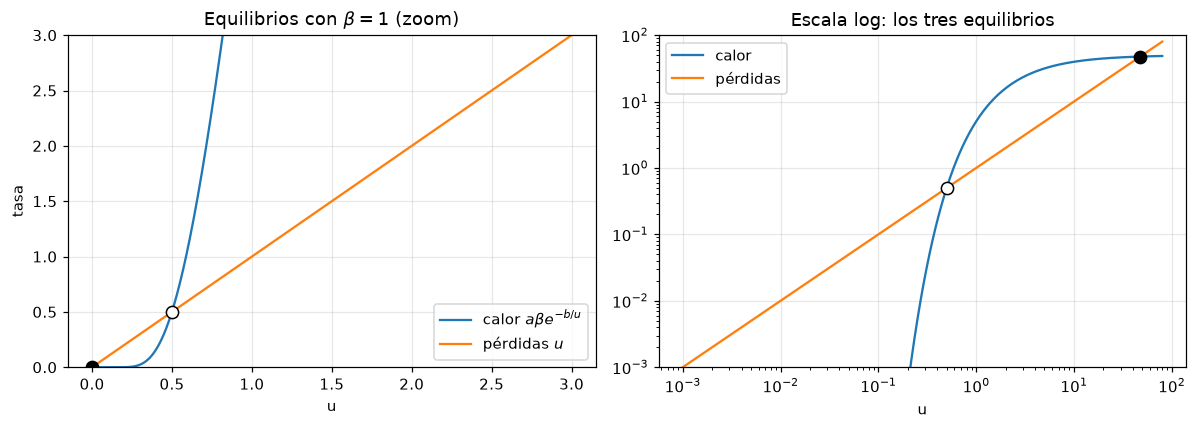

u* =    0.0000  ->  T* =    300.0 K   f'(u*) = -1.000   estable
u* =    0.4993  ->  T* =    449.8 K   f'(u*) = +3.607   INESTABLE
u* =   47.6436  ->  T* =  14593.1 K   f'(u*) = -0.952   estable


In [4]:
eqs = frozen_fuel_equilibria(d.a, d.b, 1.0)
u_plot = np.linspace(0, 3, 600)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(u_plot, d.a * reaction_rate_u(u_plot, d.b), label=r"calor $a\beta e^{-b/u}$")
ax[0].plot(u_plot, u_plot, label="pérdidas $u$")
for eq in eqs:
    if eq.u <= u_plot[-1]:
        ax[0].plot(eq.u, eq.u, "o", color="k", mfc="k" if eq.stable else "w", ms=8)
ax[0].set(xlabel="u", ylabel="tasa", title=r"Equilibrios con $\beta = 1$ (zoom)", ylim=(0, 3))
ax[0].legend()

u_wide = np.geomspace(1e-3, 80, 800)
ax[1].loglog(u_wide, d.a * reaction_rate_u(u_wide, d.b) + 1e-12, label="calor")
ax[1].loglog(u_wide, u_wide, label="pérdidas")
for eq in eqs[1:]:
    ax[1].plot(eq.u, eq.u, "o", color="k", mfc="k" if eq.stable else "w", ms=8)
ax[1].set(xlabel="u", title="Escala log: los tres equilibrios", ylim=(1e-3, 100))
ax[1].legend()
plt.tight_layout()
plt.show()

for eq in eqs:
    print(f"u* = {eq.u:9.4f}  ->  T* = {float(u_to_T(eq.u, p)):8.1f} K   f'(u*) = {float(frozen_fuel_df(eq.u, d.a, d.b, 1.0)):+.3f}   {'estable' if eq.stable else 'INESTABLE'}")

### Tabla de signos y línea de fase

Se evalúa $f$ en un punto de cada intervalo entre equilibrios. Si $f > 0$, $u$ crece; si $f < 0$, decrece.

| Intervalo | u de prueba | signo de f(u) | u(τ) |
|---|---|---|---|
| (0.000, 0.499) | 0.250 | − | decrece ↓ |
| (0.499, 47.644) | 4.877 | + | crece ↑ |
| (47.644, ∞) | 58.351 | − | decrece ↓ |

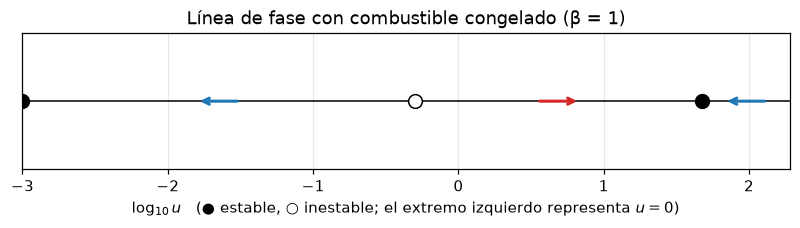

In [5]:
roots = [eq.u for eq in eqs]
edges = roots + [roots[-1] * 1.5]
lines = ["| Intervalo | u de prueba | signo de f(u) | u(τ) |", "|---|---|---|---|"]
for lo, hi in zip(edges[:-1], edges[1:]):
    probe = np.sqrt(lo * hi) if lo > 0 else hi / 2
    s = float(frozen_fuel_f(probe, d.a, d.b, 1.0))
    hi_txt = f"{hi:.3f}" if hi != edges[-1] else "∞"
    lines.append(f"| ({lo:.3f}, {hi_txt}) | {probe:.3f} | {'+' if s > 0 else '−'} | {'crece ↑' if s > 0 else 'decrece ↓'} |")
display(Markdown("\n".join(lines)))

fig, ax = plt.subplots(figsize=(9, 1.6))
ax.axhline(0, color="k", lw=1)
xs = np.log10([1e-3] + roots[1:] + [roots[-1] * 4])
ax.set_xlim(xs[0], xs[-1])
for lo, hi in zip(xs[:-1], xs[1:]):
    s = float(frozen_fuel_f(10 ** ((lo + hi) / 2), d.a, d.b, 1.0))
    mid = (lo + hi) / 2
    ax.annotate("", xy=(mid + 0.15 * np.sign(s), 0), xytext=(mid - 0.15 * np.sign(s), 0),
                arrowprops=dict(arrowstyle="->", lw=2, color="C3" if s > 0 else "C0"))
ax.plot(xs[0], 0, "o", color="k", ms=9)
for eq in eqs[1:]:
    ax.plot(np.log10(eq.u), 0, "o", color="k", mfc="k" if eq.stable else "w", ms=9)
ax.set_yticks([])
ax.set_xlabel(r"$\log_{10} u$   (● estable, ○ inestable; el extremo izquierdo representa $u = 0$)")
ax.set_title("Línea de fase con combustible congelado (β = 1)")
plt.show()

**Lectura:**
- $u = 0$ (ambiente) es **estable**: una perturbación pequeña se enfría y desaparece.
- El equilibrio intermedio $u_{ig}$ es **inestable** y es el **umbral de ignición**: por debajo la celda se apaga, por encima se enciende sola.
- El equilibrio alto es la combustión estacionaria si el combustible no se agotara. En la realidad $\beta$ cae y la celda nunca llega ahí; la sección 4 muestra el pico real.

In [6]:
u_ig = ignition_threshold(d.a, d.b)
print(f"Umbral de ignición: u_ig = {u_ig:.4f}  ->  T_ig = {float(u_to_T(u_ig, p)):.0f} K")

Umbral de ignición: u_ig = 0.4993  ->  T_ig = 450 K


### Bifurcación respecto a la cantidad de combustible

Ahora $\beta$ es el parámetro. La curva de equilibrios $u^*(\beta)$ tiene forma de S. Los equilibrios intermedio y alto nacen juntos en una **bifurcación silla-nodo** donde la curva de calor es tangente a la recta. Imponiendo $f = 0$ y $f' = 0$ a la vez:

$$u = a\beta e^{-b/u}, \quad 1 = a\beta e^{-b/u}\frac{b}{u^2} \;\Rightarrow\; u = b, \quad \beta^* = \frac{e\, b}{a}$$

Si $\beta < \beta^*$, la única opción es apagarse: **ninguna ignición prende una celda con tan poco combustible**. Este es el fundamento teórico del experimento de umbral de densidad. El umbral para que el fuego se **propague** es mayor, porque además hay que calentar a la vecina (notebook 02).

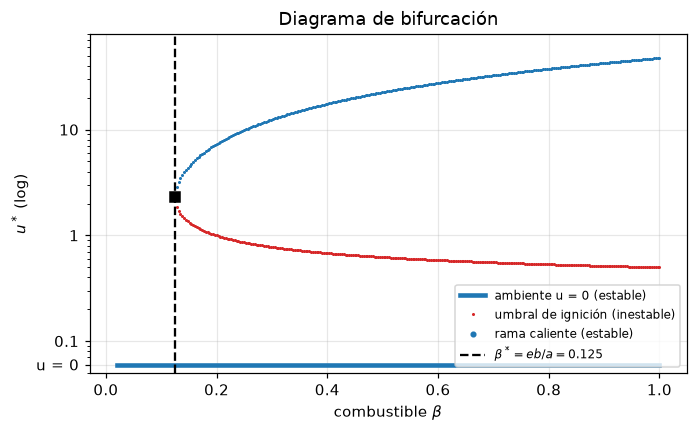

beta* = 0.1250  (con u* = b = 2.3 -> T = 990 K en la tangencia)


In [7]:
beta_c = critical_fuel(d.a, d.b)
betas = np.linspace(0.02, 1.0, 300)
stable_pts, unstable_pts = [], []
for bt in betas:
    for eq in frozen_fuel_equilibria(d.a, d.b, bt)[1:]:
        (stable_pts if eq.stable else unstable_pts).append((bt, eq.u))
s_arr, u_arr = np.array(stable_pts), np.array(unstable_pts)

U_FLOOR = 0.06  # u = 0 cannot be drawn on a log axis
fig, ax = plt.subplots(figsize=(7, 4))
ax.set_yscale("log")
ax.plot(betas, np.full_like(betas, U_FLOOR), "C0", lw=3, label="ambiente u = 0 (estable)")
ax.plot(s_arr[:, 0], s_arr[:, 1], "C0.", ms=2)
ax.plot(u_arr[:, 0], u_arr[:, 1], "C3.", ms=2, label="umbral de ignición (inestable)")
ax.plot([], [], "C0.", label="rama caliente (estable)")
ax.axvline(beta_c, color="k", ls="--", label=rf"$\beta^* = eb/a = {beta_c:.3f}$")
ax.plot(beta_c, d.b, "ks")
ax.set(xlabel=r"combustible $\beta$", ylabel=r"$u^*$ (log)", title="Diagrama de bifurcación", ylim=(0.05, 80))
ax.set_yticks([U_FLOOR, 0.1, 1, 10], ["u = 0", "0.1", "1", "10"])
ax.legend(loc="lower right", fontsize=8)
plt.show()
print(f"beta* = {beta_c:.4f}  (con u* = b = {d.b} -> T = {float(u_to_T(d.b, p)):.0f} K en la tangencia)")

## 4. Plano de fase del sistema acoplado $(u, \beta)$

$$u' = a\beta e^{-b/u} - u, \qquad \beta' = -e\,\beta\, e^{-b/u}$$

- Nulclina de $u$: $\beta = u\, e^{b/u}/a$.
- Nulclina de $\beta$: $\beta = 0$ o $u = 0$.

Los únicos equilibrios son $(0, \beta_0)$ (cualquier combustible a temperatura ambiente) y $(0, 0)$. El sistema es **excitable**: una perturbación pequeña vuelve sola, una que supera la nulclina de $u$ hace una gran excursión (la celda arde) y termina con poco combustible.

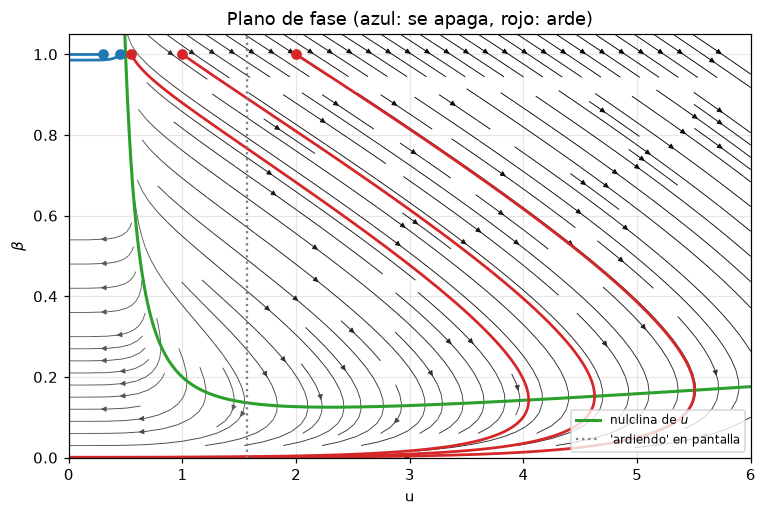

In [8]:
def rhs(_, y):
    du, db = cell_rhs_u(np.array([y[0]]), np.array([y[1]]), d)
    return [du[0], db[0]]

def burn(u0, beta0=1.0, tau_end=10.0):
    return solve_ivp(rhs, (0, tau_end), [u0, beta0], method="LSODA", rtol=1e-8, atol=1e-10, max_step=0.01)

U, Bt = np.meshgrid(np.linspace(0.0, 6.0, 48), np.linspace(0.0, 1.05, 40))
dU, dB = cell_rhs_u(U.ravel(), Bt.ravel(), d)
dU, dB = dU.reshape(U.shape), dB.reshape(U.shape)

fig, ax = plt.subplots(figsize=(8, 5))
speed = np.hypot(dU, dB)
ax.streamplot(U, Bt, dU, dB, color=np.log10(speed + 1e-6), cmap="Greys", density=1.2, linewidth=0.6, arrowsize=0.7)
u_nc = np.linspace(0.15, 6, 400)
ax.plot(u_nc, u_nc * np.exp(d.b / u_nc) / d.a, "C2", lw=2, label="nulclina de $u$")
for u0, c in zip([0.3, 0.45, 0.55, 1.0, 2.0], ["C0", "C0", "C3", "C3", "C3"]):
    s = burn(u0)
    ax.plot(s.y[0], s.y[1], color=c, lw=1.8)
    ax.plot(u0, 1.0, "o", color=c)
ax.axvline(u_burn, color="gray", ls=":", label="'ardiendo' en pantalla")
ax.set(xlim=(0, 6), ylim=(0, 1.05), xlabel="u", ylabel=r"$\beta$", title="Plano de fase (azul: se apaga, rojo: arde)")
ax.legend(loc="lower right", fontsize=8)
plt.show()

### Umbral de ignición numérico

Con el sistema acoplado buscamos por bisección la menor $u_0$ (con $\beta_0$ dado) tal que la celda arde, es decir, que consume más de la mitad de su combustible. Lo comparamos con el umbral de combustible congelado $u_{ig}(\beta_0)$.

In [9]:
def ignites(u0, beta0):
    s = burn(u0, beta0, tau_end=20)
    return s.y[1, -1] < 0.5 * beta0

def numeric_threshold(beta0, lo=1e-3, hi=5.0, it=40):
    if not ignites(hi, beta0):
        return np.nan
    for _ in range(it):
        mid = 0.5 * (lo + hi)
        lo, hi = (lo, mid) if ignites(mid, beta0) else (mid, hi)
    return hi

beta_grid = np.array([0.15, 0.2, 0.3, 0.5, 0.7, 1.0])
num = np.array([numeric_threshold(b0) for b0 in beta_grid])
frz = np.array([ignition_threshold(d.a, d.b, b0) or np.nan for b0 in beta_grid])

lines = ["| β₀ | u_ig congelado | T_ig congelado (K) | u_ig acoplado | T_ig acoplado (K) |", "|---|---|---|---|---|"]
for b0, uf, un in zip(beta_grid, frz, num):
    lines.append(f"| {b0:.2f} | {uf:.3f} | {float(u_to_T(uf, p)):.0f} | {un:.3f} | {float(u_to_T(un, p)):.0f} |")
display(Markdown("\n".join(lines)))

| β₀ | u_ig congelado | T_ig congelado (K) | u_ig acoplado | T_ig acoplado (K) |
|---|---|---|---|---|
| 0.15 | 1.329 | 699 | 1.104 | 631 |
| 0.20 | 0.998 | 599 | 1.007 | 602 |
| 0.30 | 0.777 | 533 | 0.843 | 553 |
| 0.50 | 0.623 | 487 | 0.647 | 494 |
| 0.70 | 0.555 | 467 | 0.563 | 469 |
| 1.00 | 0.499 | 450 | 0.503 | 451 |

Para $\beta_0 \ge 0.2$, el umbral acoplado queda ligeramente por encima del congelado, porque mientras la celda se calienta ya gasta algo de combustible. Con $\beta_0 = 1$ la diferencia es mínima y el análisis de combustible congelado es una buena aproximación. Cerca de $\beta^*$ los dos umbrales crecen mucho y se separan: ahí la celda puede consumir la mitad de su combustible en una combustión lenta mientras se enfría, sin llegar a encenderse de verdad, y el criterio numérico deja de distinguir los dos casos.

## 5. Evolución de una celda en unidades físicas y elección de parámetros

Encendemos una celda con el doble del umbral y la seguimos en segundos y Kelvin. Comprobamos que el pico cae dentro de la escala de cuantización del contrato ($T_{U8,min}$ = 300 K, $T_{U8,max}$ = 1500 K).

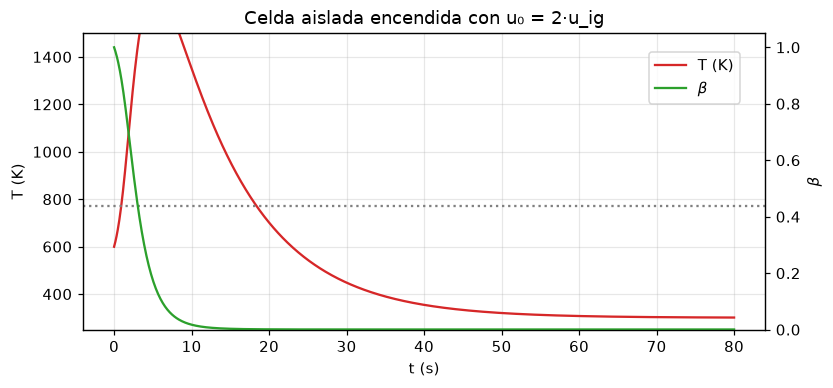

Pico: 1687 K | combustible restante: 0.001 | 'ardiendo' durante 17.4 s


In [10]:
s = burn(2 * u_ig, 1.0, tau_end=8)
t_s = s.t * time_scale(p)
T_K = u_to_T(s.y[0], p)
burning = t_s[T_K > T_BURNING]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t_s, T_K, "C3", label="T (K)")
ax.axhline(T_BURNING, color="gray", ls=":")
ax.set(xlabel="t (s)", ylabel="T (K)", ylim=(250, T_U8_MAX))
ax2 = ax.twinx()
ax2.plot(t_s, s.y[1], "C2", label=r"$\beta$")
ax2.set(ylabel=r"$\beta$", ylim=(0, 1.05))
ax2.grid(False)
ax.set_title("Celda aislada encendida con u₀ = 2·u_ig")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.85))
plt.show()

print(f"Pico: {T_K.max():.0f} K | combustible restante: {s.y[1, -1]:.3f} | 'ardiendo' durante {burning[-1]-burning[0] if len(burning) else 0:.1f} s")

Una celda encendida de golpe con mucho calor arde con todo su combustible a la vez, y su pico puede pasar de 1500 K: la cuantización lo recorta y se pinta como el máximo. Dentro de un frente no ocurre así: la celda se precalienta poco a poco por difusión, empieza a quemar antes de llegar al pico y el máximo es menor. Lo que importa para la simulación es el comportamiento dentro del frente, así que los valores por defecto se calibraron con el prototipo 1D (notebook 02) para que se cumplan cuatro condiciones:

- el pico quede entre ≈1300 y 1400 K, dentro de la escala de cuantización;
- el combustible quemado quede por debajo del 10 % (umbral visual de "quemado");
- el frente se propague con $\beta_0 = 1$ y se apague para combustibles bajos, para que el umbral de densidad sea interesante;
- la temperatura de ignición quede por debajo del umbral visual de "ardiendo".

### Sensibilidad del umbral a cada parámetro

In [11]:
lines = ["| Parámetro | Valor | a | b | e | T_ig (K) | β* |", "|---|---|---|---|---|---|---|"]
for name in ["A", "B", "C"]:
    lo, hi = PARAM_RANGES[name]
    for v in (lo, getattr(p, name), hi):
        q = p.with_(**{name: v})
        dq = to_dimensionless(q)
        ui = ignition_threshold(dq.a, dq.b)
        Ti = f"{float(u_to_T(ui, q)):.0f}" if ui is not None else "—"
        lines.append(f"| {name} | {v:g} | {dq.a:.1f} | {dq.b:.2f} | {dq.e:.1f} | {Ti} | {critical_fuel(dq.a, dq.b):.3f} |")
display(Markdown("\n".join(lines)))

| Parámetro | Valor | a | b | e | T_ig (K) | β* |
|---|---|---|---|---|---|---|
| A | 500 | 16.7 | 2.30 | 8.0 | 521 | 0.375 |
| A | 1500 | 50.0 | 2.30 | 8.0 | 450 | 0.125 |
| A | 3000 | 100.0 | 2.30 | 8.0 | 426 | 0.063 |
| B | 300 | 50.0 | 1.00 | 8.0 | 353 | 0.054 |
| B | 690 | 50.0 | 2.30 | 8.0 | 450 | 0.125 |
| B | 1200 | 50.0 | 4.00 | 8.0 | 609 | 0.217 |
| C | 0.02 | 250.0 | 2.30 | 40.0 | 405 | 0.025 |
| C | 0.1 | 50.0 | 2.30 | 8.0 | 450 | 0.125 |
| C | 0.5 | 10.0 | 2.30 | 1.6 | 599 | 0.625 |

- **A** (calor liberado): más calor baja el umbral de ignición y el combustible mínimo.
- **B** (activación): la reacción se vuelve más "de umbral"; sube tanto la temperatura de ignición como $\beta^*$.
- **C** (pérdidas): más enfriamiento hace más difícil encender una celda.
- $\varepsilon$ no cambia los equilibrios con combustible congelado, pero decide cuánto dura el fuego y qué pico alcanza.

## Parámetros elegidos

In [12]:
units = {"kappa": "m²/s", "A": "K/s", "B": "K", "C": "1/s", "eps": "1/s", "T_inf": "K"}
lines = ["| Parámetro | Por defecto | Mínimo | Máximo | Unidad |", "|---|---|---|---|---|"]
for name, (lo, hi) in PARAM_RANGES.items():
    lines.append(f"| {name} | {getattr(p, name):g} | {lo:g} | {hi:g} | {units[name]} |")
display(Markdown("\n".join(lines)))

| Parámetro | Por defecto | Mínimo | Máximo | Unidad |
|---|---|---|---|---|
| kappa | 0.5 | 0.1 | 2 | m²/s |
| A | 1500 | 500 | 3000 | K/s |
| B | 690 | 300 | 1200 | K |
| C | 0.1 | 0.02 | 0.5 | 1/s |
| eps | 0.8 | 0.2 | 3 | 1/s |
| T_inf | 300 | 270 | 320 | K |